# TP Jour 2 — Modèle d'Exécution Spark, Jointures Multi-Datasets & Couche Silver (Delta Lake)

### Objectifs de la séance
1. Observer la **Lazy Evaluation** et distinguer transformations **Narrow** vs **Wide (Shuffle)** sur **Spark Web UI** (`http://localhost:4040`).
2. Profiler la qualité de vos tables **Bronze** (issues d'un ou **plusieurs datasets Kaggle**), nettoyer les anomalies, typer fortement les colonnes et harmoniser les **clés de jointure inter-sources**.
3. Mettre en œuvre une **jointure distribuée multi-datasets maîtrisée** (`BroadcastHashJoin` via `F.broadcast` pour un référentiel/dataset compact, ou `SortMergeJoin` entre deux grandes sources) **en contrôlant la cardinalité (absence d'explosion N-à-M)**.
4. Sauvegarder votre table analytique enrichie dans **`/lakehouse/silver/`** et expérimenter les garanties **ACID de Delta Lake** (`_delta_log`, **Schema Enforcement**, **`MERGE INTO`**, **Time Travel**).

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from delta.tables import DeltaTable

spark = (
    SparkSession.builder
    .appName("J2_Spark_Delta_Silver")
    .getOrCreate()
)

print("Session Spark active — Spark UI : http://localhost:4040")

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-19c4774b-04a4-4416-bf4c-0e0f344c9f30;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found

Session Spark active — Spark UI : http://localhost:4040


## 1. Chargement de vos tables Bronze (Multi-Datasets / Multi-Tables) & Diagnostic Qualité

### Exercice 1.1 — Charger toutes vos tables Bronze et profiler valeurs manquantes / doublons
1. Chargez dans `bronze_dfs` votre table de faits principale ainsi que la (ou les) table(s) secondaire(s) à joindre depuis `/lakehouse/bronze/<nom_table>`.
2. Comptez le nombre de valeurs `NULL` sur vos colonnes clés (en particulier les **clés de jointure**) ainsi que les doublons éventuels.

In [2]:
BRONZE_TABLES: dict[str, str] = {
    "main": "/lakehouse/bronze/accidents",       # Faits : 1 ligne = 1 accident
    "secondary": "/lakehouse/bronze/vehicles",   # 1 ligne = 1 véhicule impliqué (relation 1-N)
}

assert len(BRONZE_TABLES) > 0, "TODO : Renseignez vos chemins Delta Bronze dans `BRONZE_TABLES`."
bronze_dfs = {alias: spark.read.format("delta").load(path) for alias, path in BRONZE_TABLES.items()}
for alias, df in bronze_dfs.items():
    print(f"[{alias}] {BRONZE_TABLES[alias]} -> {df.count():,} lignes | colonnes : {df.columns[:8]}")

df_bronze = bronze_dfs.get("main")
JOIN_KEY = "accident_index"

# --- Diagnostic des NULL : une seule passe Spark par table (une agrégation qui compte toutes les colonnes) ---
data_cols = [c for c in df_bronze.columns if not c.startswith("_")]   # on ignore les colonnes techniques _ingested_at...
total = df_bronze.count()
null_counts = df_bronze.select(
    [F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c) for c in data_cols]
).first().asDict()

null_report = (
    spark.createDataFrame([(c, int(n or 0)) for c, n in null_counts.items()], ["colonne", "nb_nulls"])
    .withColumn("pct_nulls", F.round(F.col("nb_nulls") / total * 100, 2))
    .orderBy(F.desc("nb_nulls"))
)
null_report.show(truncate=False)

# --- Diagnostic des doublons et de l'unicité de la clé, sur chaque table ---
for alias, df in bronze_dfs.items():
    n = df.count()
    n_dup_rows = n - df.select([c for c in df.columns if not c.startswith("_")]).distinct().count()
    n_null_key = df.filter(F.col(JOIN_KEY).isNull()).count()
    n_distinct_key = df.select(JOIN_KEY).distinct().count()
    print(f"[{alias}] lignes={n:,} | doublons complets={n_dup_rows:,} | "
          f"{JOIN_KEY} NULL={n_null_key:,} | clés distinctes={n_distinct_key:,} "
          f"| ratio lignes/clé={n / max(n_distinct_key, 1):.2f}")


26/11/17 15:41:19 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

[main] /lakehouse/bronze/accidents -> 2,047,256 lignes | colonnes : ['accident_index', '1st_road_class', '1st_road_number', '2nd_road_class', '2nd_road_number', 'accident_severity', 'carriageway_hazards', 'date']


[secondary] /lakehouse/bronze/vehicles -> 2,177,205 lignes | colonnes : ['accident_index', 'age_band_of_driver', 'age_of_vehicle', 'driver_home_area_type', 'driver_imd_decile', 'engine_capacity_cc', 'hit_object_in_carriageway', 'hit_object_off_carriageway']


+-------------------------------------------+--------+---------+
|colonne                                    |nb_nulls|pct_nulls|
+-------------------------------------------+--------+---------+
|2nd_road_class                             |844272  |41.24    |
|2nd_road_number                            |17593   |0.86     |
|pedestrian_crossing_physical_facilities    |3560    |0.17     |
|pedestrian_crossing_human_control          |2920    |0.14     |
|did_police_officer_attend_scene_of_accident|278     |0.01     |
|longitude                                  |175     |0.01     |
|latitude                                   |174     |0.01     |
|location_easting_osgr                      |164     |0.01     |
|location_northing_osgr                     |164     |0.01     |
|inscotland                                 |53      |0.0      |
|speed_limit                                |37      |0.0      |
|1st_road_number                            |2       |0.0      |
|special_conditions_at_si

[main] lignes=2,047,256 | doublons complets=0 | accident_index NULL=0 | clés distinctes=2,047,256 | ratio lignes/clé=1.00


[secondary] lignes=2,177,205 | doublons complets=0 | accident_index NULL=0 | clés distinctes=1,488,981 | ratio lignes/clé=1.46


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


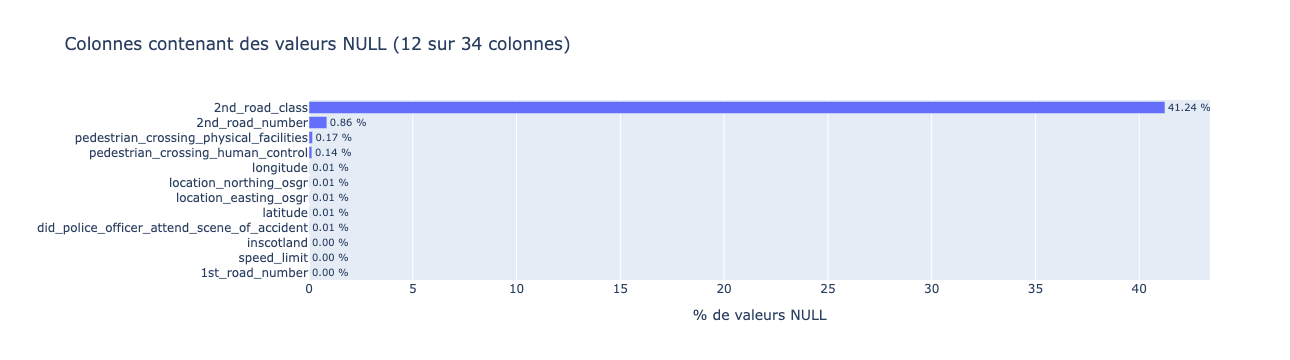

In [3]:
# Graphique 1 — Taux de valeurs NULL par colonne (table accidents Bronze)
# `null_report` ne contient qu'une ligne par colonne (~35 lignes) : toPandas() sans risque
import plotly.express as px

pdf_nulls = (null_report.filter(F.col("nb_nulls") > 0)
             .orderBy("pct_nulls")
             .toPandas())

fig = px.bar(
    pdf_nulls, x="pct_nulls", y="colonne", orientation="h", text="pct_nulls",
    hover_data=["nb_nulls"],
    labels={"pct_nulls": "% de valeurs NULL", "colonne": ""},
    title=f"Colonnes contenant des valeurs NULL ({len(pdf_nulls)} sur {len(data_cols)} colonnes)",
)
fig.update_traces(texttemplate="%{text:.2f} %", textposition="outside")
fig.show()

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


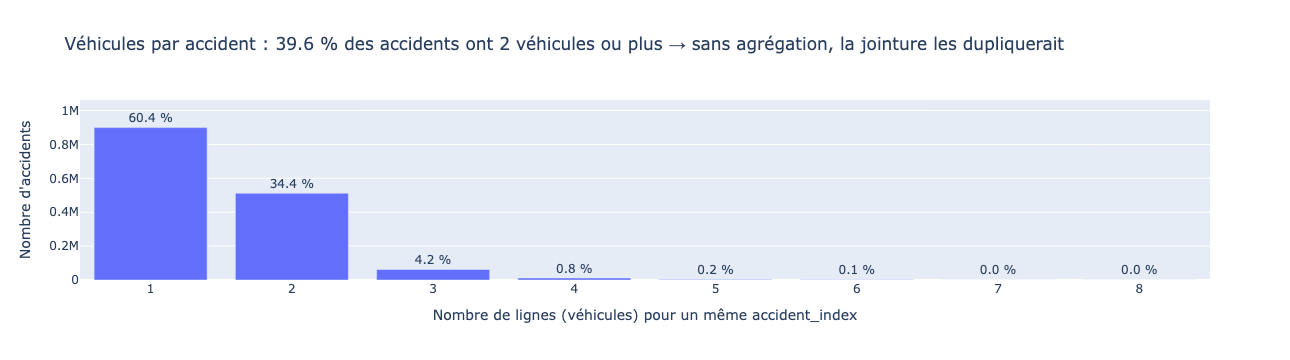

In [4]:
# Graphique 2 — Nombre de véhicules par accident dans la table vehicles (justifie la pré-agrégation)
# Double agrégation Spark : véhicules par accident, puis nombre d'accidents par valeur -> quelques lignes seulement
import plotly.express as px

pdf_veh = (bronze_dfs["secondary"]
           .groupBy(JOIN_KEY).agg(F.count("*").alias("nb_vehicules"))
           .groupBy("nb_vehicules").agg(F.count("*").alias("nb_accidents"))
           .orderBy("nb_vehicules")
           .toPandas())
pdf_veh["pct_accidents"] = (pdf_veh["nb_accidents"] / pdf_veh["nb_accidents"].sum() * 100).round(2)
pct_multi = pdf_veh.loc[pdf_veh["nb_vehicules"] >= 2, "pct_accidents"].sum()

fig = px.bar(
    pdf_veh[pdf_veh["nb_vehicules"] <= 8], x="nb_vehicules", y="nb_accidents", text="pct_accidents",
    labels={"nb_vehicules": "Nombre de lignes (véhicules) pour un même accident_index",
            "nb_accidents": "Nombre d'accidents"},
    title=f"Véhicules par accident : {pct_multi:.1f} % des accidents ont 2 véhicules ou plus "
          f"→ sans agrégation, la jointure les dupliquerait",
)
fig.update_traces(texttemplate="%{text:.1f} %", textposition="outside")
fig.show()

## 2. Harmonisation Inter-Datasets, Nettoyage & Jointure Distribuée (`BroadcastHashJoin` / `SortMergeJoin`)

### Bonnes pratiques de jointure entre plusieurs datasets hétérogènes :
1. **Harmonisation des clés de jointure (*Key Alignment*)** : deux datasets Kaggle d'auteurs différents n'ont presque jamais exactement le même format de clé :
   - *Axe temporel* : ramenez les horodatages à la même granularité et au même fuseau (`F.to_date(...)`, `F.date_trunc("hour", ...)` ou format `yyyy-MM`).
   - *Axe géographique / catégoriel* : normalisez la casse, les espaces et les codes (`F.upper(F.trim(col))`, code ISO pays/région, code postal ou grille `F.round(lat, 2)`).
2. **Prévention des explosions N-à-M** : avant un `LEFT JOIN` de la table principale (`N` lignes) vers un second dataset, assurez-vous que la clé de jointure est **unique côté table secondaire** via une pré-agrégation métier (`groupBy(join_keys).agg(...)`) ou `dropDuplicates(join_keys)` ! Vérifiez systématiquement que le nombre de lignes après `LEFT JOIN` n'explose pas.
3. **Choix de la stratégie physique Spark** :
   - **Table secondaire compacte (< quelques dizaines de Mo)** : forcez **`F.broadcast(df_sec)`** pour obtenir un `BroadcastHashJoin` sans *Shuffle* de la grande table.
   - **Deux grands datasets volumineux** : laissez Spark exécuter un `SortMergeJoin` distribué (optimisé dynamiquement par *Adaptive Query Execution*).

### Exercice 2.1 — Nettoyer, harmoniser vos clés, joindre vos sources et écrire `/lakehouse/silver/<table_silver>`
1. Nettoyez vos tables (`dropDuplicates`, filtrage d'anomalies, typage fort `F.to_timestamp` / `F.to_date` / numériques) et harmonisez la clé de jointure commune.
2. Créez au moins **2 nouvelles colonnes métier dérivées** (dont idéalement un indicateur combinant vos deux sources !) utiles pour les Jours 3 & 4.
3. Réalisez la jointure (avec `F.broadcast(...)` sur une table de dimension/dataset secondaire compact), contrôlez le **taux de rapprochement (*match rate*)** ainsi que l'absence de duplication N-M, et affichez `.explain("simple")`.
4. Écrivez la table enrichie au format **Delta** dans **`/lakehouse/silver/<votre_table>`**.

In [5]:
SILVER_MAIN_PATH = "/lakehouse/silver/accidents_enriched"
JOIN_KEY = "accident_index"
MISSING = "Data missing or out of range"


def null_sentinels(df):
    """Remplace la valeur sentinelle du dataset par un vrai NULL sur les colonnes texte."""
    return df.select([
        F.when(F.col(c) == MISSING, None).otherwise(F.col(c)).alias(c) if t == "string" else F.col(c)
        for c, t in df.dtypes
    ])


# ---------- 1) Nettoyage de la table principale : accidents ----------
df_acc = (
    null_sentinels(bronze_dfs["main"])
    .withColumn(JOIN_KEY, F.upper(F.trim(F.col(JOIN_KEY))))                    # harmonisation de la clé
    .filter(F.col(JOIN_KEY).isNotNull())
    .dropDuplicates([JOIN_KEY])                                                 # 1 ligne = 1 accident
    # Typage fort (try_* : renvoie NULL au lieu de planter en mode ANSI)
    .withColumn("accident_date", F.try_to_date("date", "yyyy-MM-dd"))
    .withColumn("accident_ts", F.try_to_timestamp(
        F.concat_ws(" ", "date", "time"), F.lit("yyyy-MM-dd HH:mm")))
    .withColumn("latitude", F.col("latitude").try_cast("double"))
    .withColumn("longitude", F.col("longitude").try_cast("double"))
    .withColumn("number_of_casualties", F.col("number_of_casualties").try_cast("int"))
    .withColumn("number_of_vehicles", F.col("number_of_vehicles").try_cast("int"))
    .withColumn("speed_limit", F.col("speed_limit").try_cast("int"))
    .withColumn("year", F.col("year").try_cast("int"))
    # Filtrage des anomalies
    .filter(F.col("accident_date").isNotNull())
    .filter(F.col("number_of_vehicles") > 0)
    .filter(F.col("latitude").isNull() | F.col("latitude").between(49, 61))    # bornes du Royaume-Uni
    # Colonnes métier dérivées (source accidents)
    .withColumn("accident_hour", F.hour("accident_ts"))
    .withColumn("is_weekend", F.dayofweek("accident_date").isin(1, 7))          # 1 = dimanche, 7 = samedi
    .withColumn("is_night", F.col("light_conditions").startswith("Darkness"))
    .drop("date", "time")
)
count_before_join = df_acc.count()

# ---------- 2) Pré-agrégation de la table secondaire : vehicles ----------
df_veh_agg = (
    null_sentinels(bronze_dfs["secondary"])
    .withColumn(JOIN_KEY, F.upper(F.trim(F.col(JOIN_KEY))))
    .filter(F.col(JOIN_KEY).isNotNull())
    .withColumn("age_of_vehicle", F.col("age_of_vehicle").try_cast("int"))
    .groupBy(JOIN_KEY)                                                          # => clé UNIQUE, pas d'explosion N-M
    .agg(
        F.count("*").alias("nb_vehicules_enregistres"),
        F.round(F.avg("age_of_vehicle"), 1).alias("age_moyen_vehicules"),
        F.max(F.col("age_band_of_driver").isin("16 - 20", "21 - 25").cast("int"))
         .cast("boolean").alias("has_young_driver"),
    )
)

# ---------- 3) Jointure + indicateur croisant les 2 sources ----------
df_silver = (
    df_acc.join(df_veh_agg, on=JOIN_KEY, how="left")                            # SortMergeJoin (2 grosses tables)
    .withColumn("victimes_par_vehicule",
                F.round(F.col("number_of_casualties") / F.col("nb_vehicules_enregistres"), 2))
)

# Contrôle du match rate
matched = df_silver.filter(F.col("nb_vehicules_enregistres").isNotNull()).count()
print(f"Lignes avant join : {count_before_join:,} | accidents rapprochés : {matched:,} "
      f"| match rate : {matched / count_before_join:.2%}")

assert df_silver is not None, "TODO : Construisez le DataFrame nettoyé et joint `df_silver`."
df_silver.explain("simple")

# ---------- 4) Écriture Delta en couche Silver ----------
(df_silver.write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(SILVER_MAIN_PATH))

silver_count = spark.read.format("delta").load(SILVER_MAIN_PATH).count()
if count_before_join is not None:
    assert silver_count <= count_before_join, (
        f"Alerte explosion N-M : {silver_count:,} lignes après jointure > {count_before_join:,} lignes avant jointure !"
    )
print(f"Table Silver écrite dans {SILVER_MAIN_PATH} : {silver_count:,} lignes")


Lignes avant join : 2,047,256 | accidents rapprochés : 1,389,724 | match rate : 67.88%
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [accident_index#3297, 1st_road_class#3890, 1st_road_number#3892, 2nd_road_class#3894, 2nd_road_number#3896, accident_severity#3898, carriageway_hazards#3900, day_of_week#3904, did_police_officer_attend_scene_of_accident#3906, junction_control#3908, junction_detail#3910, latitude#3300, light_conditions#3914, local_authority_district#3916, local_authority_highway#3918, location_easting_osgr#3920, location_northing_osgr#3922, longitude#3301, lsoa_of_accident_location#3926, number_of_casualties#3302, number_of_vehicles#3303, pedestrian_crossing_human_control#3932, pedestrian_crossing_physical_facilities#3934, police_force#3936, road_surface_conditions#3938, ... 19 more fields]
   +- BroadcastHashJoin [accident_index#3297], [accident_index#3557], LeftOuter, BuildRight, false, false
      :- Project [accident_index#3297, 1st_road_class#3890

Table Silver écrite dans /lakehouse/silver/accidents_enriched : 2,047,256 lignes


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


 year  accidents  accidents_rapproches  accidents_dans_vehicles  match_rate_pct
 2004        0.0                   0.0                  99257.0             NaN
 2005   198735.0               93951.0                  93951.0            47.3
 2006   189161.0               94817.0                  94817.0            50.1
 2007   182115.0              101470.0                 101470.0            55.7
 2008   170591.0               97130.0                  97130.0            56.9
 2009   163554.0              127059.0                 127059.0            77.7
 2010   154414.0              123729.0                 123729.0            80.1
 2011   151474.0              122404.0                 122404.0            80.8
 2012   145571.0              117703.0                 117703.0            80.9
 2013   138660.0              114138.0                 114138.0            82.3
 2014   146322.0              120646.0                 120646.0            82.5
 2015   140056.0              140056.0  

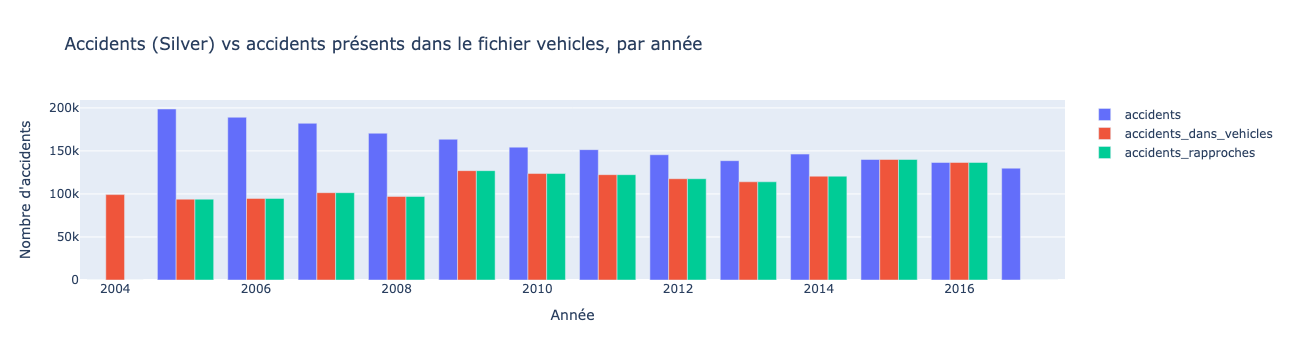

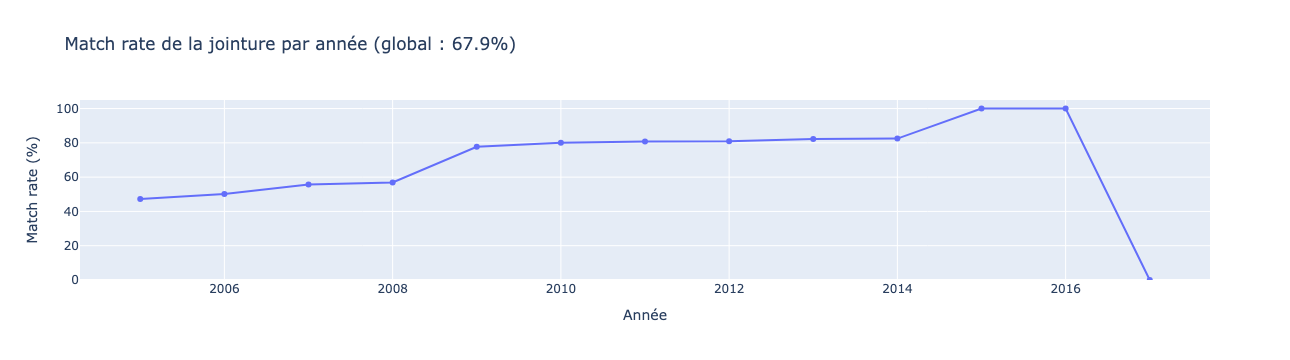

In [6]:
# Graphique 3 — Match rate par année : pourquoi seulement ~68 % des accidents trouvent leurs véhicules ?
import plotly.express as px

# a) Côté accidents (Silver) : accidents et accidents rapprochés par année
pdf_acc_year = (spark.read.format("delta").load(SILVER_MAIN_PATH)
                .groupBy("year")
                .agg(F.count("*").alias("accidents"),
                     F.sum(F.col("nb_vehicules_enregistres").isNotNull().cast("int")).alias("accidents_rapproches"))
                .toPandas())

# b) Côté vehicles (Bronze) : nombre d'accidents distincts présents dans le fichier vehicles, par année
pdf_veh_year = (bronze_dfs["secondary"]
                .withColumn("year", F.col("year").try_cast("int"))
                .groupBy("year")
                .agg(F.countDistinct(JOIN_KEY).alias("accidents_dans_vehicles"))
                .toPandas())

pdf_year = (pdf_acc_year.merge(pdf_veh_year, on="year", how="outer")
            .fillna(0).sort_values("year"))
pdf_year["year"] = pdf_year["year"].astype(int)
pdf_year["match_rate_pct"] = (pdf_year["accidents_rapproches"] / pdf_year["accidents"].where(pdf_year["accidents"] > 0) * 100).round(1)
print(pdf_year.to_string(index=False))

# Comparaison des volumes par année
fig = px.bar(
    pdf_year.melt(id_vars="year",
                  value_vars=["accidents", "accidents_dans_vehicles", "accidents_rapproches"],
                  var_name="série", value_name="nombre"),
    x="year", y="nombre", color="série", barmode="group",
    labels={"year": "Année", "nombre": "Nombre d'accidents", "série": ""},
    title="Accidents (Silver) vs accidents présents dans le fichier vehicles, par année",
)
fig.show()

# Match rate par année
fig = px.line(
    pdf_year.dropna(subset=["match_rate_pct"]), x="year", y="match_rate_pct", markers=True,
    labels={"year": "Année", "match_rate_pct": "Match rate (%)"},
    title=f"Match rate de la jointure par année (global : {matched / count_before_join:.1%})",
)
fig.update_yaxes(range=[0, 105])
fig.show()

## 3. Garanties Transactionnelles ACID de Delta Lake

### Exercice 3.1 — Explorer `_delta_log` et vérifier le *Schema Enforcement*
1. Lisez et affichez les premières lignes du fichier JSON de transaction `00000000000000000000.json` situé dans `{SILVER_MAIN_PATH}/_delta_log/`.
2. Tentez d'insérer (`mode("append")`) un petit DataFrame artificiel au schéma incompatible dans `SILVER_MAIN_PATH` et interceptez l'exception levée par Delta Lake.

In [7]:
# 1. Lecture directe du journal transactionnel JSON sur HDFS
spark.read.text(f"{SILVER_MAIN_PATH}/_delta_log/00000000000000000000.json").show(8, truncate=110)

# 2. TODO : Tester le Schema Enforcement avec un DataFrame au mauvais schéma dans un bloc try/except
bad_df = spark.createDataFrame([("test_1", "colonne_intruse")], ["fake_id", "intruder_col"])
try:
    bad_df.write.format("delta").mode("append").save(SILVER_MAIN_PATH)
except Exception as e:
    print("Schema Enforcement validé — écriture invalide bloquée :", str(e).splitlines()[0])

+--------------------------------------------------------------------------------------------------------------+
|                                                                                                         value|
+--------------------------------------------------------------------------------------------------------------+
|{"commitInfo":{"timestamp":1794910979830,"operation":"WRITE","operationParameters":{"mode":"Overwrite","par...|
|{"metaData":{"id":"eb973e04-48d5-4ab8-a1d9-848ef6098faa","format":{"provider":"parquet","options":{}},"sche...|
|                                                      {"protocol":{"minReaderVersion":1,"minWriterVersion":2}}|
|{"add":{"path":"part-00000-bddf7672-2a17-4980-81a0-80d5e0e7b1d9-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00001-849a22b2-903d-46ba-a177-832a46245f00-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00002-81bef8c0-17f2-46e7-a72b-5c37315b2f7a-c000.snappy.parquet","partition

### Exercice 3.2 — Upsert (`MERGE INTO`) et Voyage dans le Temps (`VERSION AS OF`)
1. Prélevez un petit lot de lignes existantes dans votre table Silver (ou simulez un lot correctif + 1 nouvelle ligne) et appliquez un **`MERGE INTO`** via `DeltaTable.forPath(spark, SILVER_MAIN_PATH)` (`whenMatchedUpdate` / `whenNotMatchedInsert`).
2. Affichez l'historique des commits avec `DESCRIBE HISTORY` et interrogez la version initiale de la table via `.option("versionAsOf", 0)` pour démontrer l'auditabilité temporelle !

In [8]:
# TODO : Exécuter un MERGE INTO sur `SILVER_MAIN_PATH` puis comparer versionAsOf=0 et la version courante
target_delta = DeltaTable.forPath(spark, SILVER_MAIN_PATH)
df_current = spark.read.format("delta").load(SILVER_MAIN_PATH)

# ---------- 1) Construire le lot de mises à jour (simulation) ----------
# a) 5 accidents existants : correction du nombre de victimes (+1)
sample_rows = df_current.limit(5).collect()          # collect() = on fige les valeurs AVANT le merge
updated_keys = [r[JOIN_KEY] for r in sample_rows]

df_corrections = (
    spark.createDataFrame(sample_rows, schema=df_current.schema)
    .withColumn("number_of_casualties", F.col("number_of_casualties") + 1)
)

# b) 1 nouvel accident : copie d'une ligne existante avec une clé inventée
df_new = (
    spark.createDataFrame(sample_rows[:1], schema=df_current.schema)
    .withColumn(JOIN_KEY, F.lit("TEST_NEW_001"))
)

df_updates = (
    df_corrections.unionByName(df_new)
    .withColumn("victimes_par_vehicule",                 # on garde l'indicateur dérivé cohérent
                F.round(F.col("number_of_casualties") / F.col("nb_vehicules_enregistres"), 2))
)
print("Lot de mises à jour :")
df_updates.select(JOIN_KEY, "number_of_casualties", "victimes_par_vehicule").show()

# ---------- 2) MERGE INTO ----------
(
    target_delta.alias("tgt")
    .merge(df_updates.alias("src"), f"tgt.{JOIN_KEY} = src.{JOIN_KEY}")
    .whenMatchedUpdate(set={                                   # clé trouvée -> correction
        "number_of_casualties": "src.number_of_casualties",
        "victimes_par_vehicule": "src.victimes_par_vehicule",
    })
    .whenNotMatchedInsertAll()                                 # clé absente -> insertion de toute la ligne
    .execute()
)

# ---------- 3) Comparaison version 0 / version courante (Time Travel) ----------
keys_to_check = updated_keys + ["TEST_NEW_001"]
cols = [JOIN_KEY, "number_of_casualties", "victimes_par_vehicule"]

print("AVANT (versionAsOf = 0) :")
(spark.read.format("delta").option("versionAsOf", 0).load(SILVER_MAIN_PATH)
    .filter(F.col(JOIN_KEY).isin(keys_to_check)).select(cols).orderBy(JOIN_KEY).show())

print("APRÈS (version courante) :")
(spark.read.format("delta").load(SILVER_MAIN_PATH)
    .filter(F.col(JOIN_KEY).isin(keys_to_check)).select(cols).orderBy(JOIN_KEY).show())


history_df = spark.sql(f"DESCRIBE HISTORY delta.`{SILVER_MAIN_PATH}`")
history_df.select("version", "timestamp", "operation", "operationMetrics").show(truncate=80)
assert history_df.count() >= 2, "TODO : Exécutez au moins une opération MERGE/UPDATE pour créer une version >= 1 !"

Lot de mises à jour :
+--------------+--------------------+---------------------+
|accident_index|number_of_casualties|victimes_par_vehicule|
+--------------+--------------------+---------------------+
| 200501BS00015|                   2|                 NULL|
| 200501BS70002|                   2|                  2.0|
| 200501BS70007|                   2|                 0.67|
| 200501BS70009|                   2|                 NULL|
| 200501BS70036|                   2|                  2.0|
|  TEST_NEW_001|                   1|                 NULL|
+--------------+--------------------+---------------------+



26/11/17 15:42:33 WARN MapPartitionsRDD: RDD 428 was locally checkpointed, its lineage has been truncated and cannot be recomputed after unpersisting


AVANT (versionAsOf = 0) :


+--------------+--------------------+---------------------+
|accident_index|number_of_casualties|victimes_par_vehicule|
+--------------+--------------------+---------------------+
| 200501BS00015|                   1|                 NULL|
| 200501BS70002|                   1|                  1.0|
| 200501BS70007|                   1|                 0.33|
| 200501BS70009|                   1|                 NULL|
| 200501BS70036|                   1|                  1.0|
+--------------+--------------------+---------------------+

APRÈS (version courante) :
+--------------+--------------------+---------------------+
|accident_index|number_of_casualties|victimes_par_vehicule|
+--------------+--------------------+---------------------+
| 200501BS00015|                   2|                 NULL|
| 200501BS70002|                   2|                  2.0|
| 200501BS70007|                   2|                 0.67|
| 200501BS70009|                   2|                 NULL|
| 200501BS70

In [9]:
DeltaTable.forPath(spark, SILVER_MAIN_PATH).restoreToVersion(0)

DataFrame[table_size_after_restore: bigint, num_of_files_after_restore: bigint, num_removed_files: bigint, num_restored_files: bigint, removed_files_size: bigint, restored_files_size: bigint]